In [1]:
main_dir = "/home/gap2/Downloads/PPRL-Dev-main/results/random_configurations/"
datasets= ["D2", "D3", "D4", "D8", "D9", "D10"]

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PRECISION = "Precision %"
RECALL = "Recall %"

def pareto_front(df, recall_threshold=85):
    # Keep only rows above the recall threshold
    df = df[df[RECALL] > recall_threshold]
    
    # Sort by precision (descending)
    df = df.sort_values(PRECISION, ascending=False)

    best_recall = -np.inf
    keep = []

    for idx, row in df.iterrows():
        if row[RECALL] > best_recall:
            keep.append(idx)
            best_recall = row[RECALL]

    return df.loc[keep].sort_values(PRECISION)

In [3]:
from numpy import trapz

def hypervolume(front):

    front = front.sort_values(PRECISION)

    return trapz(
        front[RECALL],
        front[PRECISION]
    )

In [4]:
def dominates(a, b):
    return (
        a[PRECISION] >= b[PRECISION]
        and a[RECALL] >= b[RECALL]
        and (
            a[PRECISION] > b[PRECISION]
            or a[RECALL] > b[RECALL]
        )
    )


def dominance_count(frontA, frontB):
    count = 0

    for _, pointB in frontB.iterrows():
        for _, pointA in frontA.iterrows():
            if dominates(pointA, pointB):
                count += 1
                break

    return count


def dominance_percentage(frontA, frontB):
    n = len(frontB)
    if n == 0:
        return 0.0

    return 100.0 * dominance_count(frontA, frontB) / n






D2


/tmp/ipykernel_10603/2280741016.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


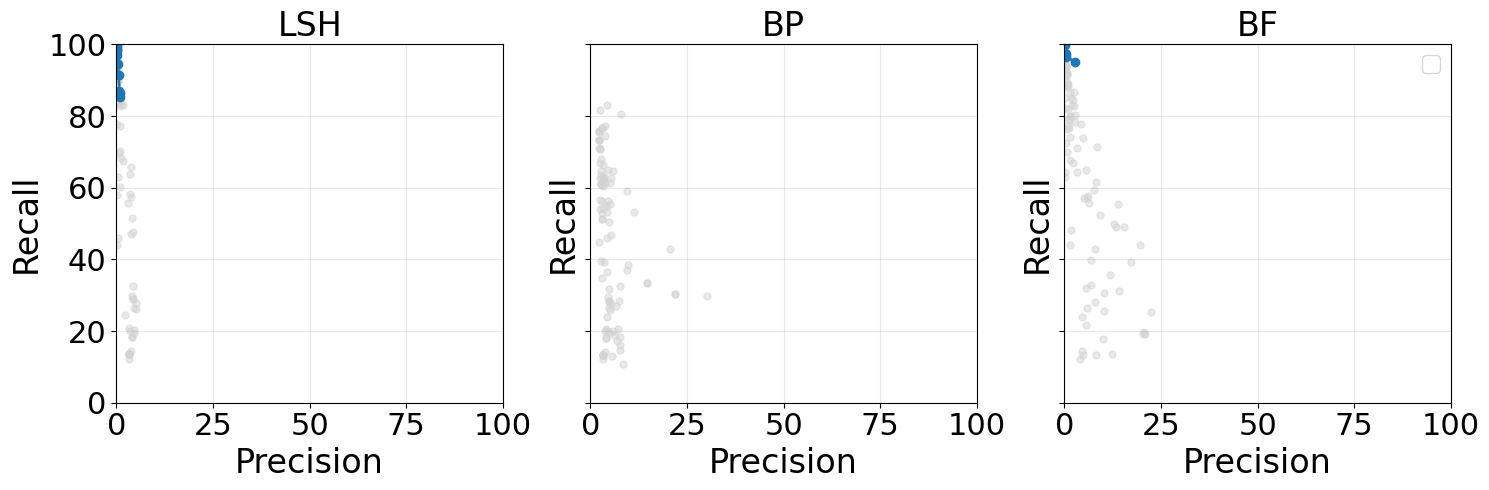

/tmp/ipykernel_10603/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_10603/2280741016.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


LSH 86.21395
BP 0.0
BF 260.5686
       LSH    BP     BF
LSH      -  0.0%  33.3%
BP    0.0%     -   0.0%
BF   50.0%  0.0%      -





D3


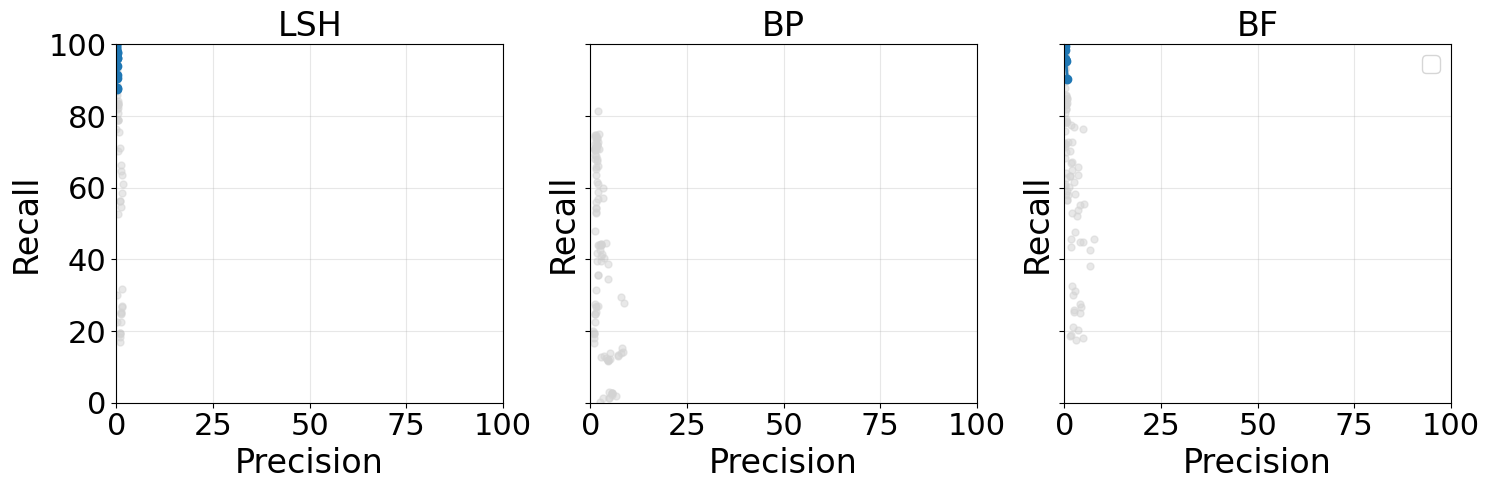

/tmp/ipykernel_10603/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_10603/2280741016.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


LSH 21.95105
BP 0.0
BF 74.6456
       LSH    BP     BF
LSH      -  0.0%  25.0%
BP    0.0%     -   0.0%
BF   80.0%  0.0%      -





D4


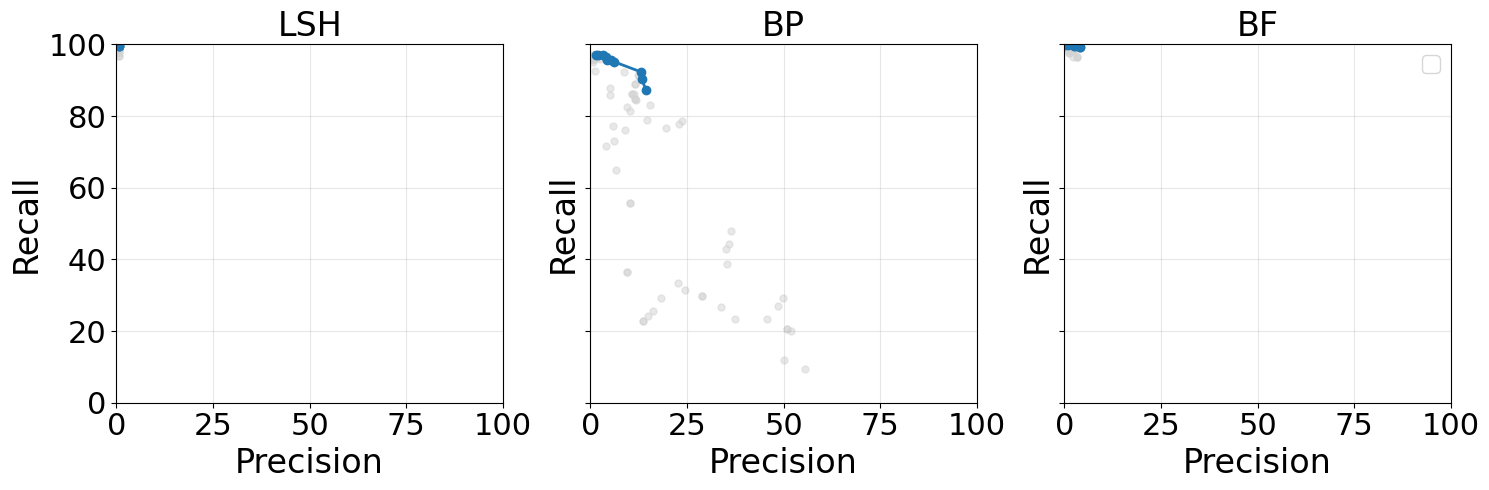

/tmp/ipykernel_10603/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_10603/2280741016.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


LSH 66.85454999999999
BP 1229.58575
BF 399.57435
        LSH     BP    BF
LSH       -   0.0%  0.0%
BP     0.0%      -  0.0%
BF   100.0%  40.0%     -





D8


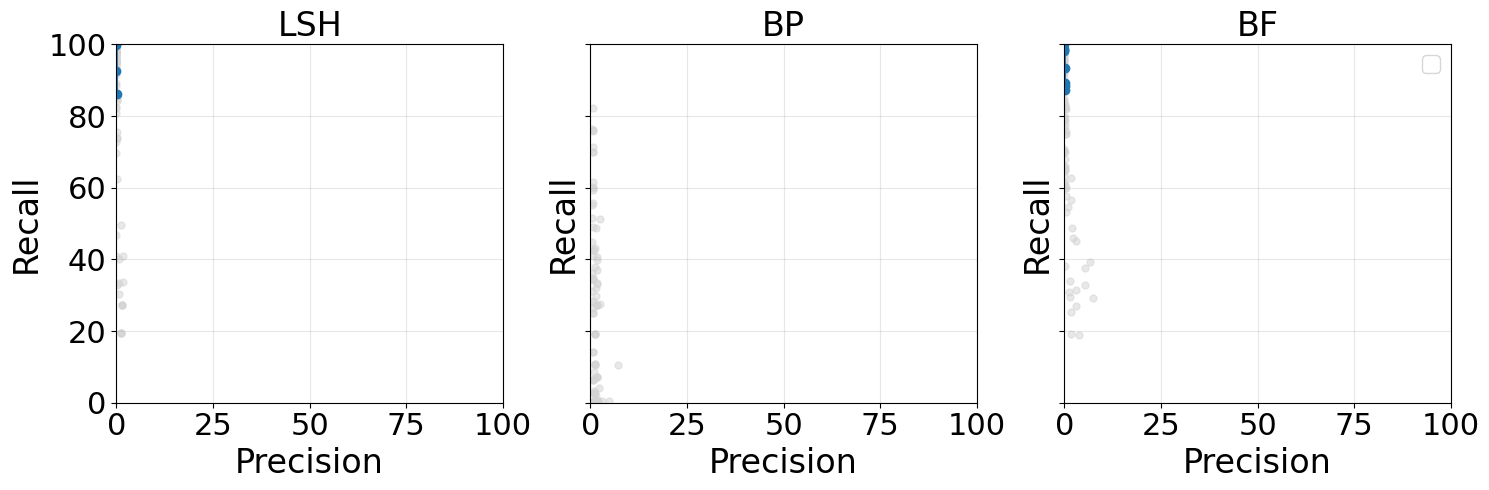

/tmp/ipykernel_10603/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_10603/2280741016.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


LSH 3.7116
BP 0.0
BF 12.521450000000002
       LSH    BP     BF
LSH      -  0.0%  25.0%
BP    0.0%     -   0.0%
BF   75.0%  0.0%      -





D9


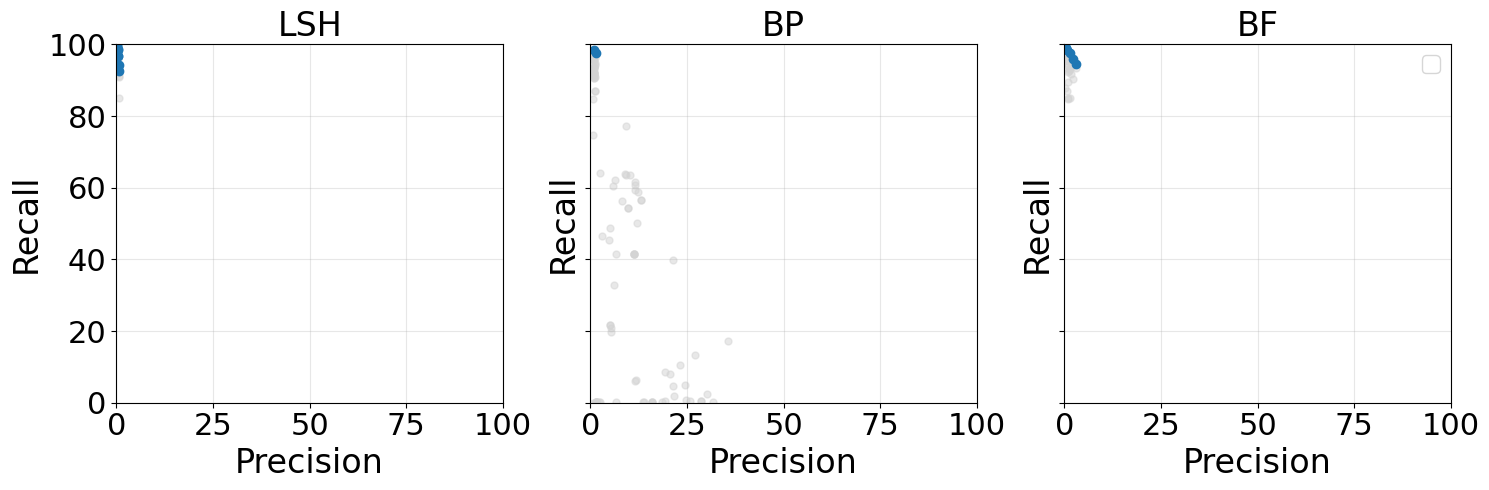

/tmp/ipykernel_10603/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_10603/2280741016.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


LSH 67.3815
BP 32.31195
BF 293.6328
       LSH     BP     BF
LSH      -   0.0%  10.0%
BP   45.5%      -  10.0%
BF   72.7%  50.0%      -





D10


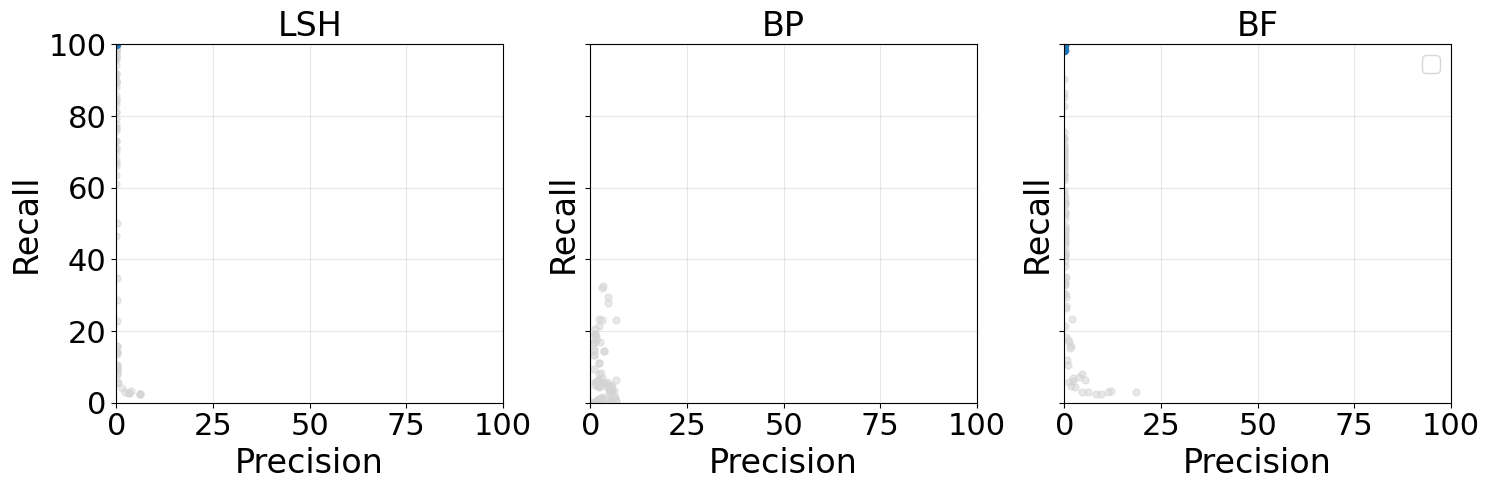

LSH 0.0
BP 0.0
BF 0.0
      LSH    BP      BF
LSH     -  0.0%  100.0%
BP   0.0%     -    0.0%
BF   0.0%  0.0%       -


/tmp/ipykernel_10603/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(


In [5]:
for dataset in datasets:
    print("\n\n\n\n\n" + dataset)
    
    files = {
        "LSH": main_dir + "lsh_blocker/" + dataset + "/lsh_blocker.csv",
        "BP": main_dir + "filtering/" + dataset + "/block_purging.csv",
        "BF": main_dir + "filtering/" + dataset + "/block_filtering.csv"
    }

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 5),
        sharex=True,
        sharey=True
    )

    pareto = {} 
    for ax, (title, filename) in zip(axes, files.items()):

        df = pd.read_csv(filename)
        pf = pareto_front(df)
        pareto[title] = pf
        
        # All experiments
        ax.scatter(
            df[PRECISION],
            df[RECALL],
            color="lightgray",
            alpha=0.5,
            s=25
        )

        # Pareto front
        ax.plot(
            pf[PRECISION],
            pf[RECALL],
            "-o",
            linewidth=2,
            markersize=6
        )

        ax.set_title(title, fontsize=24)
        ax.set_xlabel("Precision", fontsize=24)
        ax.set_ylabel("Recall", fontsize=24)
        ax.tick_params(axis='both', labelsize=22)

        ax.grid(alpha=0.3)
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 100)

    axes[0].set_ylabel("Recall")

    for ax in axes:
        ax.set_xlabel("Precision")
        
    ax.legend(fontsize=16)

    plt.tight_layout()
    plt.show()
    
    for name, pf in pareto.items():
        print(name, hypervolume(pf)) #higher is better
        
    names = list(pareto.keys())

    table = pd.DataFrame(
        index=names,
        columns=names
    )

    for A in names:
        for B in names:

            if A == B:
                table.loc[A,B] = "-"

            else:
                table.loc[A, B] = f"{dominance_percentage(pareto[A], pareto[B]):.1f}%"

    print(table)

In [6]:
from IPython.display import display, HTML

for dataset in datasets:
    all_summaries = []
    print("\n\n\n" + dataset)
    for threshold in [85, 90, 95]:
        files = {
            "LSH": main_dir + "lsh_blocker/" + dataset + "/lsh_blocker.csv",
            "BP": main_dir + "filtering/" + dataset + "/block_purging.csv",
            "BF": main_dir + "filtering/" + dataset + "/block_filtering.csv"
        }

        for name, filename in files.items():
            df = pd.read_csv(filename)
            valid = df[df["Recall %"] >= threshold]

            if valid.empty:
                continue

            best = valid.loc[valid["Precision %"].idxmax()].to_dict()
            best["Method"] = name
            best["Dataset"] = dataset

            all_summaries.append(best)

        summary_df = pd.DataFrame(all_summaries)

    display(
        HTML(
            f"""
            <div style="overflow-x:auto; width:100%;">
                {pd.DataFrame(all_summaries).to_html()}
            </div>
            """
        )
    )




D2


,name,runtime,candidate_pairs,psi,lambda,distance_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset,ratio,lsh_config
0,LSH-Blocking,0.67,95373,12.0,110.0,19.0,0.95,85.34,1.88,908,94465,920,156,"{'attributes': ['name'], 'size': 64, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",LSH,D2,NaN,NaN
1,Block Filtering,0.22,37257,NaN,NaN,NaN,2.72,95.11,5.28,1012,36245,1024,52,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",BF,D2,0.2,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}"
2,LSH-Blocking,0.72,158017,12.0,114.0,153.0,0.62,91.54,1.22,974,157043,986,90,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 7, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",LSH,D2,NaN,NaN
3,Block Filtering,0.22,37257,NaN,NaN,NaN,2.72,95.11,5.28,1012,36245,1024,52,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",BF,D2,0.2,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}"
4,LSH-Blocking,0.86,463019,9.0,134.0,102.0,0.22,96.99,0.44,1032,461987,1044,32,"{'attributes': ['name'], 'size': 256, 'offset': 0, 'num_hashes': 5, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",LSH,D2,NaN,NaN
5,Block Filtering,0.22,37257,NaN,NaN,NaN,2.72,95.11,5.28,1012,36245,1024,52,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",BF,D2,0.2,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}"





D3


,name,runtime,candidate_pairs,psi,lambda,distance_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset,ratio,lsh_config
0,LSH-Blocking,1.48,381786,12.0,114.0,153.0,0.25,87.57,0.50,965,380821,3050,137,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 9, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",LSH,D3,NaN,NaN
1,Block Filtering,0.35,125581,NaN,NaN,NaN,0.79,90.20,1.57,994,124587,3079,108,"{'attributes': ['title'], 'size': 256, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",BF,D3,0.2,"{'psi': 12, 'lambda': 110, 'distance_threshold': 76}"
2,LSH-Blocking,1.43,783331,12.0,110.0,38.0,0.13,90.65,0.25,999,782332,3084,103,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",LSH,D3,NaN,NaN
3,Block Filtering,0.35,125581,NaN,NaN,NaN,0.79,90.20,1.57,994,124587,3079,108,"{'attributes': ['title'], 'size': 256, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",BF,D3,0.2,"{'psi': 12, 'lambda': 110, 'distance_threshold': 76}"
4,LSH-Blocking,1.67,2181473,9.0,135.0,409.0,0.05,96.19,0.10,1060,2180413,3145,42,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 20, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",LSH,D3,NaN,NaN
5,Block Filtering,0.64,263623,NaN,NaN,NaN,0.40,95.28,0.79,1050,262573,3135,52,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",BF,D3,0.5,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}"





D4


...

,name,runtime,candidate_pairs,psi,lambda,distance_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset,ratio,lsh_config
0,LSH-Blocking,8.95,1763116,19.0,125.0,204.0,0.04,86.28,0.08,736,1762380,23652,117,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 9, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",LSH,D8,NaN,NaN
1,Block Filtering,2.47,522451,NaN,NaN,NaN,0.14,87.34,0.28,745,521706,23661,108,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 6, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",BF,D8,0.6,"{'psi': 19, 'lambda': 125, 'distance_threshold': 204}"
2,LSH-Blocking,6.86,4676885,12.0,110.0,76.0,0.02,92.50,0.03,789,4676096,23705,64,"{'attributes': ['title'], 'size': 256, 'offset': 0, 'num_hashes': 3, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",LSH,D8,NaN,NaN
3,Block Filtering,4.10,2315219,NaN,NaN,NaN,0.03,93.43,0.07,797,2314422,23713,56,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",BF,D8,0.5,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}"
4,LSH-Blocking,12.09,64926499,9.0,134.0,102.0,0.00,96.83,0.00,826,64925673,23742,27,"{'attributes': ['title'], 'size': 256, 'offset': 0, 'num_hashes': 6, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",LSH,D8,NaN,NaN
5,Block Filtering,5.01,13020098,NaN,NaN,NaN,0.01,96.01,0.01,819,13019279,23735,34,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 6, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",BF,D8,0.4,"{'psi': 7, 'lambda': 147, 'distance_threshold': 256}"





D9


,name,runtime,candidate_pairs,psi,lambda,distance_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset,smoothing_factor,lsh_config,ratio
0,LSH-Blocking,31.96,309881,40.0,137.0,102.0,0.69,92.58,1.37,2133,307748,61351,171,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 15, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",LSH,D9,NaN,NaN,NaN
1,Block Purging,2.98,169916,NaN,NaN,NaN,1.32,97.48,2.61,2246,167670,61464,58,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",BP,D9,0.9,"{'psi': 20, 'lambda': 142, 'distance_threshold': 25}",NaN
2,Block Filtering,0.87,71821,NaN,NaN,NaN,3.03,94.57,5.88,2179,69642,61397,125,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",BF,D9,NaN,"{'psi': 20, 'lambda': 142, 'distance_threshold': 25}",0.2
3,LSH-Blocking,31.96,309881,40.0,137.0,102.0,0.69,92.58,1.37,2133,307748,61351,171,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 15, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",LSH,D9,NaN,NaN,NaN
4,Block Purging,2.98,169916,NaN,NaN,NaN,1.32,97.48,2.61,2246,167670,61464,58,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",BP,D9,0.9,"{'psi': 20, 'lambda': 142, 'distance_threshold': 25}",NaN
5,Block Filtering,0.87,71821,NaN,NaN,NaN,3.03,94.57,5.88,2179,69642,61397,125,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",BF,D9,NaN,"{'psi': 20, 'lambda': 142, 'distance_threshold': 25}",0.2
6,LSH-Blocking,20.66,443924,21.0,146.0,12.0,0.50,96.61,1.00,2226,441698,61444,78,"{'attributes': ['title'], 'size': 64, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",LSH,D9,NaN,NaN,NaN
7,Block Purging,2.98,169916,NaN,NaN,NaN,1.32,97.48,2.61,2246,167670,61464,58,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",BP,D9,0.9,"{'psi': 20, 'lambda': 142, 'distance_threshold': 25}",NaN
8,Block Filtering,1.74,98979,NaN,NaN,NaN,2.23,96.01,4.37,2212,96767,61430,92,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 9, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",BF,D9,NaN,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}",0.3





D10


,name,runtime,candidate_pairs,psi,lambda,distance_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset,ratio,lsh_config
0,LSH-Blocking,824.93,30666204971,7.0,147.0,128.0,0.0,100.00,0.0,22148,30666182823,27415,0,"{'attributes': ['title', 'starring'], 'size': 128, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",LSH,D10,NaN,NaN
1,Block Filtering,101.30,7579569411,NaN,NaN,NaN,0.0,98.28,0.0,21766,7579547645,27033,382,"{'attributes': ['title', 'starring'], 'size': 256, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",BF,D10,0.4,"{'psi': 7, 'lambda': 147, 'distance_threshold': 256}"
2,LSH-Blocking,824.93,30666204971,7.0,147.0,128.0,0.0,100.00,0.0,22148,30666182823,27415,0,"{'attributes': ['title', 'starring'], 'size': 128, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",LSH,D10,NaN,NaN
3,Block Filtering,101.30,7579569411,NaN,NaN,NaN,0.0,98.28,0.0,21766,7579547645,27033,382,"{'attributes': ['title', 'starring'], 'size': 256, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",BF,D10,0.4,"{'psi': 7, 'lambda': 147, 'distance_threshold': 256}"
4,LSH-Blocking,824.93,30666204971,7.0,147.0,128.0,0.0,100.00,0.0,22148,30666182823,27415,0,"{'attributes': ['title', 'starring'], 'size': 128, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",LSH,D10,NaN,NaN
5,Block Filtering,101.30,7579569411,NaN,NaN,NaN,0.0,98.28,0.0,21766,7579547645,27033,382,"{'attributes': ['title', 'starring'], 'size': 256, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",BF,D10,0.4,"{'psi': 7, 'lambda': 147, 'distance_threshold': 256}"
